In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/patient_records.csv")
print(df.columns.tolist())

['patient_id', 'first_name', 'last_name', 'gender', 'date_of_birth', 'age', 'blood_group', 'preferred_language', 'city', 'state', 'insurance_provider', 'insurance_plan', 'admission_date', 'discharge_date', 'length_of_stay_days', 'admission_type', 'department', 'attending_physician', 'primary_diagnosis', 'icd10_code', 'secondary_diagnosis', 'comorbidity_count', 'icu_admission', 'procedure_performed', 'height_cm', 'weight_kg', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate_bpm', 'temperature_c', 'spo2_pct', 'blood_glucose_mgdl', 'hba1c_pct', 'total_cholesterol_mgdl', 'hemoglobin_gdl', 'creatinine_mgdl', 'smoking_status', 'alcohol_use', 'known_allergy', 'primary_medication', 'lab_tests_ordered', 'total_bill_inr', 'insurance_covered_inr', 'patient_paid_inr', 'payment_status', 'discharge_disposition', 'readmitted_30d', 'risk_score', 'patient_satisfaction']


The dataset contains 50 columns covering patient demographics, clinical information, billing details, and outcomes.

In [3]:
df.describe()

,age,length_of_stay_days,comorbidity_count,icu_admission,height_cm,weight_kg,bmi,systolic_bp,diastolic_bp,heart_rate_bpm,...,total_cholesterol_mgdl,hemoglobin_gdl,creatinine_mgdl,lab_tests_ordered,total_bill_inr,insurance_covered_inr,patient_paid_inr,readmitted_30d,risk_score,patient_satisfaction
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,91902.000000,97000.000000,96086.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,44.739350,2.315120,1.325150,0.036910,158.555881,62.244882,24.557105,124.853470,79.412080,81.225320,...,186.206503,12.479638,1.044345,8.101080,47376.550226,28225.078685,14279.640276,0.083060,17.551530,3.913810
std,19.472329,2.950848,1.062007,0.188542,10.895614,15.326128,4.889479,17.571478,12.424227,13.502337,...,34.349080,1.967338,0.441698,4.660747,55780.707362,41337.281683,28714.577207,0.275974,10.747616,0.867761
min,1.000000,0.000000,0.000000,0.000000,56.300000,4.000000,11.900000,70.000000,40.000000,40.000000,...,100.000000,4.500000,0.300000,0.000000,1723.300000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,30.000000,0.000000,1.000000,0.000000,152.100000,52.400000,21.200000,113.000000,71.000000,72.000000,...,163.000000,11.300000,0.860000,5.000000,14974.337500,5296.547500,1258.382500,0.000000,10.000000,3.000000
50%,42.000000,1.000000,1.000000,0.000000,158.700000,62.100000,24.600000,122.000000,78.000000,80.000000,...,185.000000,12.600000,0.990000,7.000000,24677.800000,13967.360000,4719.580000,0.000000,15.000000,4.000000
75%,56.000000,3.000000,1.000000,0.000000,166.000000,72.100000,27.900000,134.000000,87.000000,89.000000,...,208.000000,13.800000,1.140000,10.000000,57102.170000,30884.162500,14459.582500,0.000000,23.000000,5.000000
max,100.000000,45.000000,8.000000,1.000000,194.900000,136.300000,43.300000,211.000000,135.000000,156.000000,...,373.000000,19.000000,9.500000,40.000000,997673.760000,844400.240000,899609.200000,1.000000,87.000000,5.000000


In [4]:
missing_pct = df.isnull().mean() * 100
missing_pct = missing_pct.sort_values(ascending=False)

print(missing_pct.head(7))


hba1c_pct                 12.145
total_cholesterol_mgdl     8.098
creatinine_mgdl            3.914
hemoglobin_gdl             3.000
blood_glucose_mgdl         2.887
date_of_birth              0.000
last_name                  0.000
dtype: float64


Some columns have missing values, so they need to be checked before further analysis.

In [5]:
df.duplicated().sum()
df["patient_id"].duplicated().sum()

np.int64(0)

There are no duplicate patient IDs in the dataset.

In [6]:
for col in ["date_of_birth", "admission_date", "discharge_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")


print(df[["date_of_birth", "admission_date", "discharge_date"]].isna().sum())

date_of_birth     0
admission_date    0
discharge_date    0
dtype: int64


The date fields were converted from strings to datetime values to validate date consistency.

In [7]:
# Should there be any admissions before the patient was born
invalid_birth = (df["admission_date"] < df["date_of_birth"]).sum()
print("Admission before date of birth:", invalid_birth)

# Discharge should always be after admission
invalid_discharge = (df["discharge_date"] < df["admission_date"]).sum()
print("Discharge before admission:", invalid_discharge)

# Bills: insurance + patient payment should equal total bill
billing_gap = df["total_bill_inr"] - df["insurance_covered_inr"] - df["patient_paid_inr"]
print("\nBilling gap (should be near 0):")
print(billing_gap.describe().round(2))

Admission before date of birth: 1
Discharge before admission: 0

Billing gap (should be near 0):
count    100000.00
mean       4871.83
std       17420.97
min          -0.00
25%           0.00
50%           0.00
75%        1982.65
max      564524.98
dtype: float64


Logic checks were performed for invalid cases, including admissions before birth, discharge before admission, and bills where insurance plus patient payment should match the total bill.

In [8]:
# How are admissions spread across years and months
df["admission_year"]  = df["admission_date"].dt.year
df["admission_month"] = df["admission_date"].dt.month_name()

print(df.groupby("admission_year").size().rename("admissions"))

admission_year
2023     5770
2024    33507
2025    33071
2026    27652
Name: admissions, dtype: int64


Admissions increased sharply from 2023 to 2024, while counts remained fairly stable between 2024 and 2025.

In [9]:
for col in ["gender", "department", "admission_type", "payment_status",
            "discharge_disposition", "smoking_status", "blood_group"]:
    print(df[col].value_counts())

gender
Male      50229
Female    49282
Other       489
Name: count, dtype: int64
department
Cardiology          15850
General Medicine    14249
Endocrinology       14020
Pulmonology         13105
Orthopedics          7855
Gastroenterology     6598
Neurology            4132
Hematology           3898
Oncology             3414
Urology              3383
General Surgery      3334
Psychiatry           2897
Nephrology           2571
Dermatology          1869
Critical Care        1448
Obstetrics            999
Pediatrics            378
Name: count, dtype: int64
admission_type
Emergency     34615
Outpatient    28070
Elective      20401
Urgent        16914
Name: count, dtype: int64
payment_status
Paid              68017
Partially Paid    13970
Pending           11988
Overdue            6025
Name: count, dtype: int64
discharge_disposition
Home                           90683
Home Health Care                4071
Skilled Nursing Facility        1981
Left Against Medical Advice     1709
Deceased    

# Distribtion of Patient Counts by Age Group

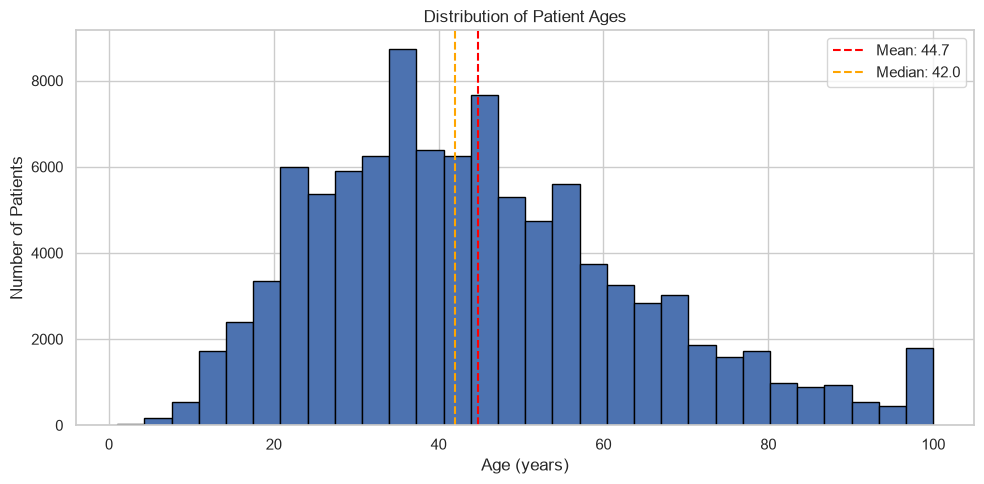

In [10]:
# Age distribution are most patients young or old
plt.figure(figsize=(10, 5))
plt.hist(df["age"], bins=30, edgecolor="black")
plt.axvline(df["age"].mean(), color="red", linestyle="--", label=f"Mean: {df['age'].mean():.1f}")
plt.axvline(df["age"].median(), color="orange", linestyle="--", label=f"Median: {df['age'].median():.1f}")
plt.title("Distribution of Patient Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.legend()
plt.tight_layout()
plt.show()

Patient ages range from about 0 to 100 years, with most admissions occurring between ages 20 and 60.

# Patient Count by Department

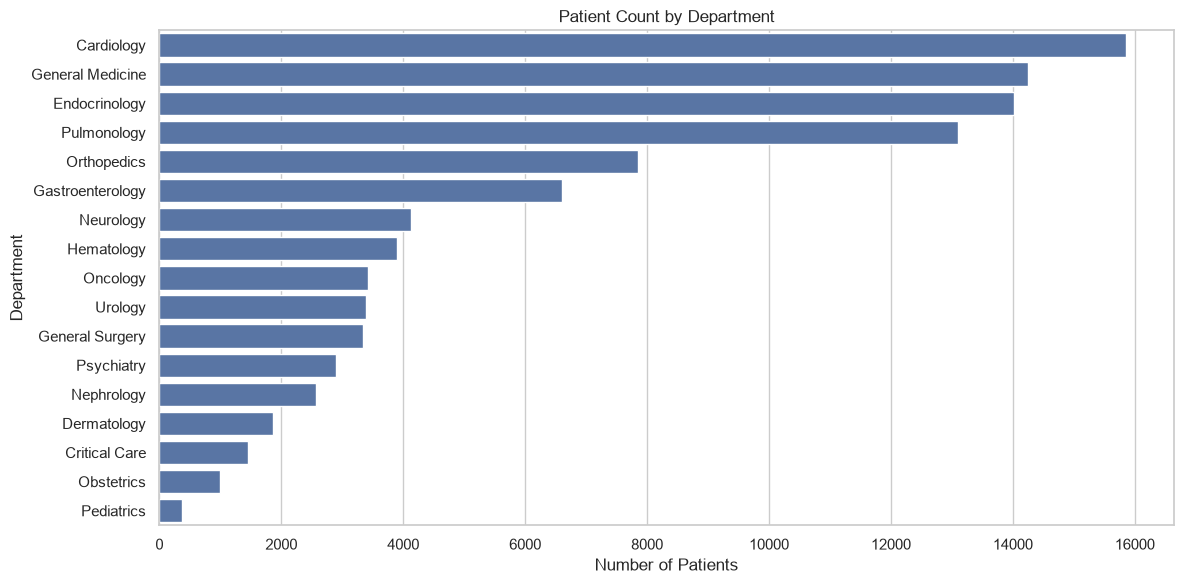

In [11]:
# Which departments handle the most patients
department_counts = df["department"].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=department_counts.values, y=department_counts.index)
plt.title("Patient Count by Department")
plt.xlabel("Number of Patients")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

Cardiology is the most heavily used department. General Medicine, Endocrinology, and Pulmonology also see high volumes, with activity concentrated in a few major specialties.

# Patient Count by Admission Type

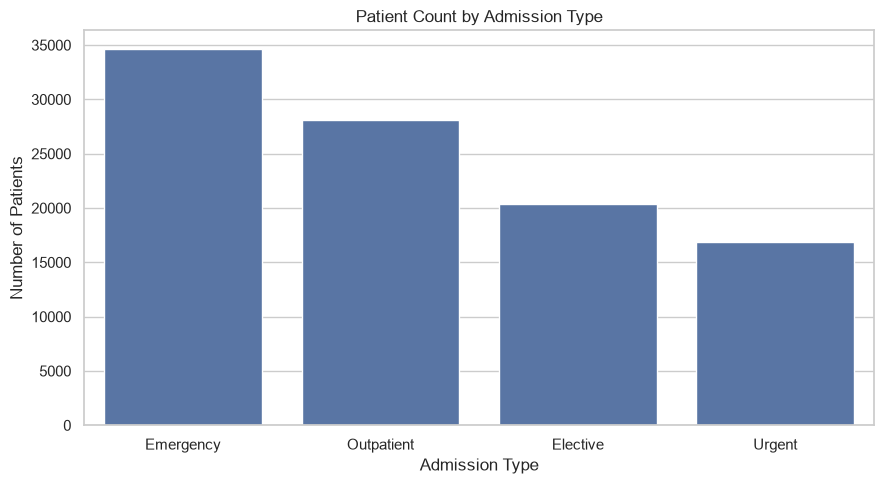

In [12]:
# Elective vs Emergency vs Urgent which is most common
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="admission_type", order=df["admission_type"].value_counts().index)
plt.title("Patient Count by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

Emergency admissions are the most common, followed by outpatient visits.

# Distribution of Hospital Bills

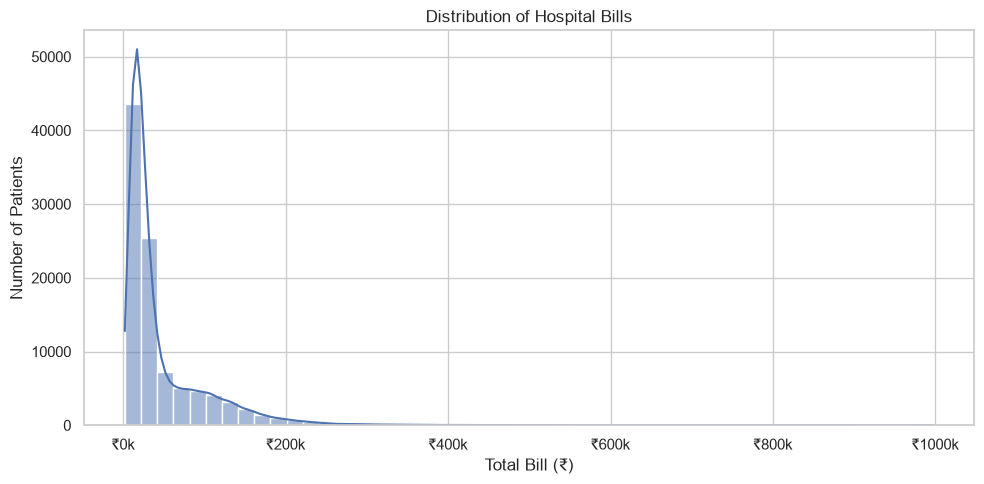

In [13]:
# How spread out are the hospital bills
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="total_bill_inr", bins=50, kde=True)
plt.title("Distribution of Hospital Bills")
plt.xlabel("Total Bill (₹)")
plt.ylabel("Number of Patients")
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"₹{x/1000:.0f}k"))
plt.tight_layout()
plt.show()

Hospital bills are right-skewed, with most patients falling in the lower billing range and only a small number of high-cost cases.

# Hospital Bills by Admission Type

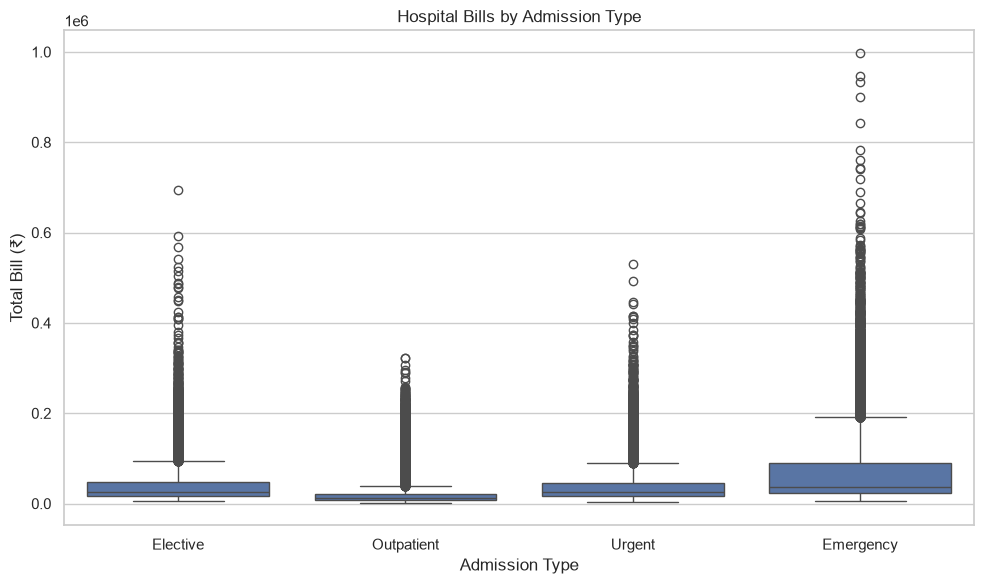

In [14]:
# Do emergency patients pay more than elective ones
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="admission_type", y="total_bill_inr")
plt.title("Hospital Bills by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Total Bill (₹)")
plt.tight_layout()
plt.show()

Emergency admissions have the highest bills, while outpatient cases are the least expensive. Emergency cases also show the greatest cost variability, and several high-value outliers appear across admission types.

# Which department generates the most revenue and has the highest average bill?

In [15]:
department_financial_summary = df.groupby("department").agg(
    total_billing   = ("total_bill_inr", "sum"),
    average_bill    = ("total_bill_inr", "mean"),
    median_bill     = ("total_bill_inr", "median"),
    patient_count   = ("patient_id", "count")
).sort_values("total_billing", ascending=False)

print(department_financial_summary.round(2))

# Critical Care has the highest average bill but fewer patients 
# so Cardiology ends up with higher total billing overall

                  total_billing  average_bill  median_bill  patient_count
department                                                               
Cardiology         8.554929e+08      53974.32     26537.90          15850
Pulmonology        8.122402e+08      61979.41     40708.04          13105
General Medicine   5.754162e+08      40382.92     23820.51          14249
Neurology          3.364134e+08      81416.59     30307.22           4132
Oncology           3.258704e+08      95451.19     90395.09           3414
Orthopedics        3.238868e+08      41233.20     22143.99           7855
General Surgery    3.014261e+08      90409.75     86884.11           3334
Endocrinology      3.012189e+08      21484.94     18706.54          14020
Nephrology         2.258096e+08      87829.49     83099.91           2571
Critical Care      1.846285e+08     127505.88     82244.52           1448
Gastroenterology   1.419423e+08      21512.94     18526.08           6598
Obstetrics         9.040184e+07      9

Cardiology generates the highest total billing (₹85.55 crore) with 15,850 patients.
Critical Care has the highest average bill (₹1,27,505.88), despite having fewer patients.
Oncology and General Surgery have consistently high average and median billing.
Endocrinology has high patient volume (14,020) but relatively low average billing (₹21,484.94).
Pediatrics has the lowest total billing (₹78.17 lakh), mainly due to its low patient count.
Cardiology shows a large difference between mean and median billing, suggesting the influence of high-cost cases.
Overall, patient volume and average treatment cost both play important roles in department-wise revenue generation.

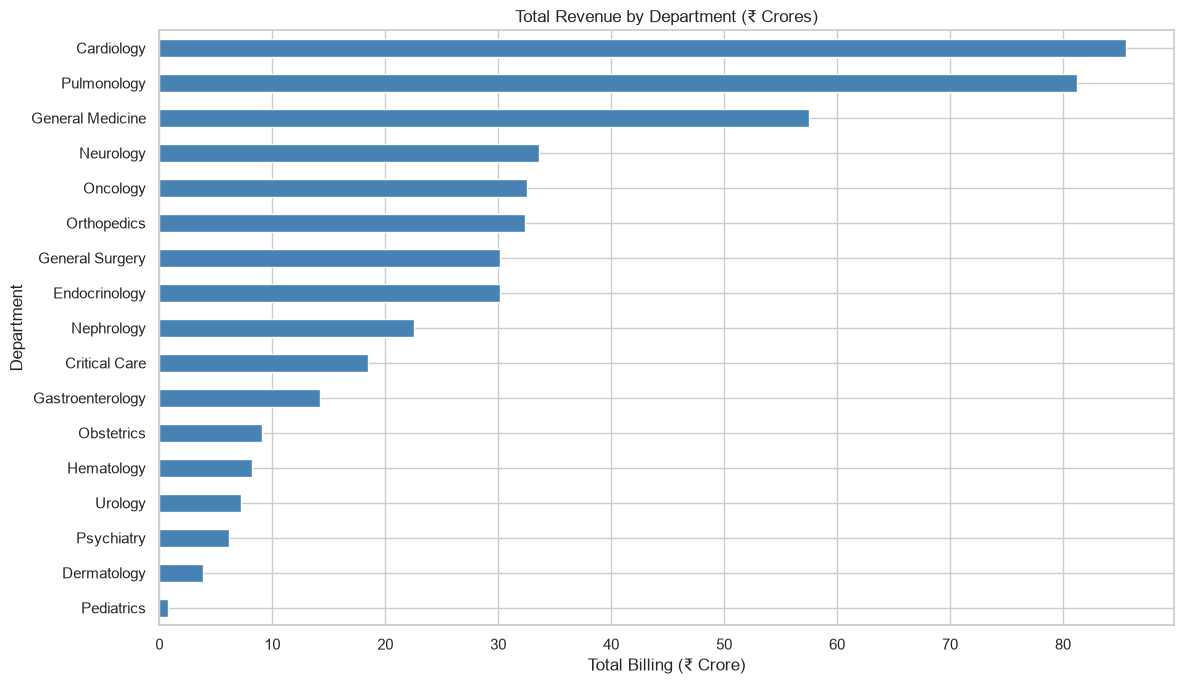

In [16]:
billing_chart = department_financial_summary["total_billing"].sort_values(ascending=True) / 10_000_000

plt.figure(figsize=(12, 7))
billing_chart.plot(kind="barh", color="steelblue")
plt.title("Total Revenue by Department (₹ Crores)")
plt.xlabel("Total Billing (₹ Crore)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

Cardiology generates the highest total revenue. Pulmonology and General Medicine also contribute significantly, and revenue is concentrated in a few major departments.

# Insurance coverage by provider

In [17]:
# Insurance coverage — how much did each provider actually cover
insurance_summary = df.groupby("insurance_provider").agg(
    patient_count           = ("patient_id", "count"),
    avg_total_bill          = ("total_bill_inr", "mean"),
    avg_insurance_covered   = ("insurance_covered_inr", "mean"),
    avg_patient_paid        = ("patient_paid_inr", "mean")
).sort_values("patient_count", ascending=False)

insurance_summary["coverage_pct"] = (
    insurance_summary["avg_insurance_covered"] / insurance_summary["avg_total_bill"] * 100
).round(1)

print(insurance_summary.round(2))

                          patient_count  avg_total_bill  \
insurance_provider                                        
Ayushman Bharat (PM-JAY)          25095        47699.84   
Self-Pay                          20905        46821.59   
Star Health                       11516        46754.35   
HDFC ERGO                          9709        47351.62   
ICICI Lombard                      8581        49011.16   
Care Health                        6698        46702.84   
Niva Bupa                          6663        46735.01   
ESIC                               6038        47538.40   
CGHS                               4795        48352.35   

                          avg_insurance_covered  avg_patient_paid  \
insurance_provider                                                  
Ayushman Bharat (PM-JAY)               41677.80           4518.05   
Self-Pay                                   0.00          34611.02   
Star Health                            29982.86          12506.29   
HDFC 

Ayushman Bharat is the most commonly used insurance provider. Self-Pay represents a large share of patients, suggesting substantial uninsured utilization. Average bills are similar across providers, while ESIC and CGHS offer the highest coverage rates. Government schemes provide stronger financial protection than private insurers, on average.

# Payment Status Distribution by Insurance Provider

payment_status            Overdue   Paid  Partially Paid  Pending
insurance_provider                                               
Ayushman Bharat (PM-JAY)     1477  17106            3493     3019
CGHS                          285   3221             681      608
Care Health                   406   4559             929      804
ESIC                          363   4125             853      697
HDFC ERGO                     584   6668            1313     1144
ICICI Lombard                 524   5877            1161     1019
Niva Bupa                     401   4580             909      773
Self-Pay                     1306  14060            2971     2568
Star Health                   679   7821            1660     1356


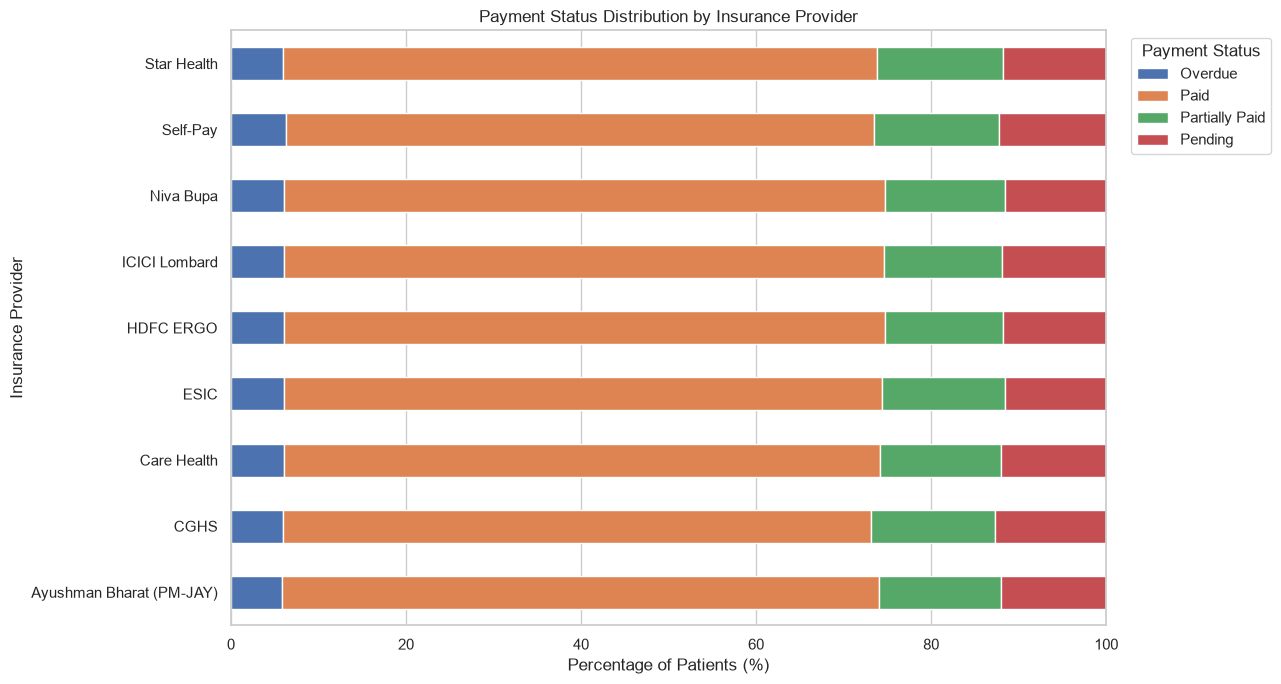

In [18]:
# Payment status breakdown by insurance provider
payment_distribution = pd.crosstab(df["insurance_provider"], df["payment_status"])
payment_percentage   = pd.crosstab(df["insurance_provider"], df["payment_status"], normalize="index") * 100
print(payment_distribution)
fig, ax = plt.subplots(figsize=(13, 7))
payment_percentage.plot(kind="barh", stacked=True, ax=ax)
ax.set_title("Payment Status Distribution by Insurance Provider")
ax.set_xlabel("Percentage of Patients (%)")
ax.set_ylabel("Insurance Provider")
ax.set_xlim(0, 100)
ax.legend(title="Payment Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



Paid bills are the dominant payment status across providers, while overdue payments are the least common. Payment behavior is broadly consistent across insurance providers, suggesting that insurance type has limited influence on completion patterns.

# Top 15 most frequent primary diagnoses

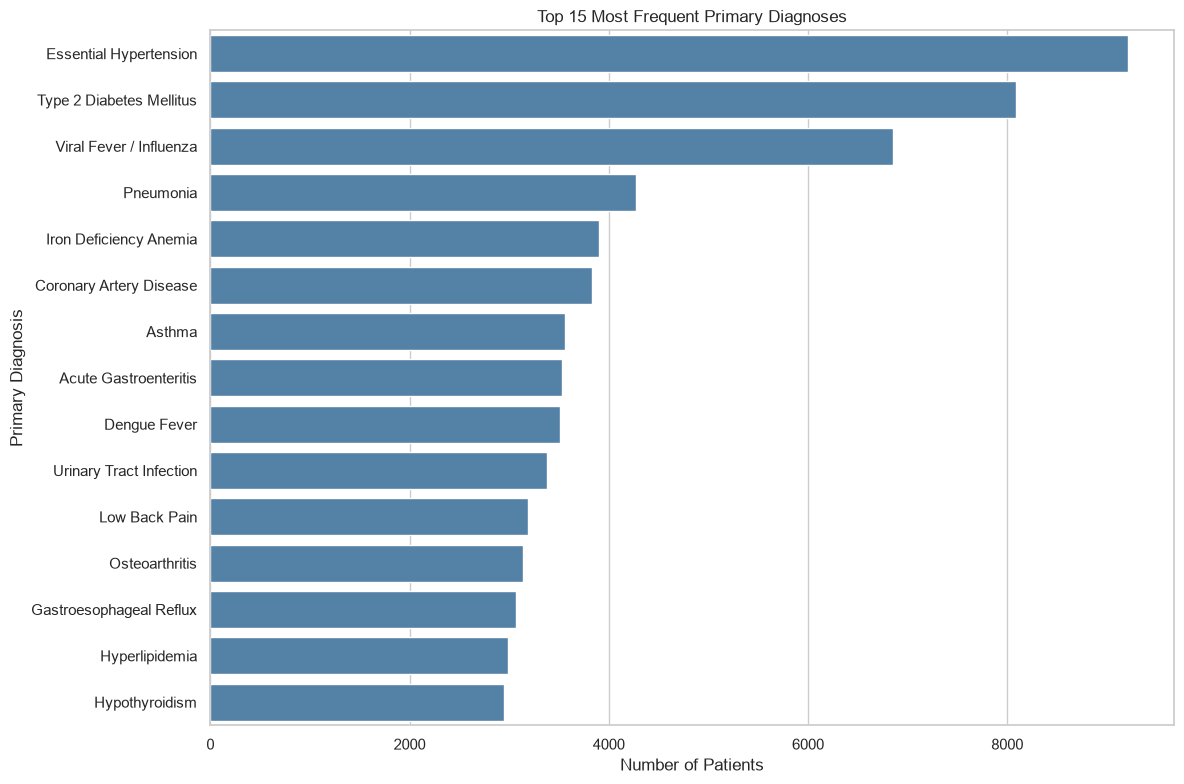

In [19]:
# Top diagnoses — what are patients mostly coming in for?
diagnosis_frequency = (
    df["primary_diagnosis"]
    .value_counts()
    .reset_index()
)
diagnosis_frequency.columns = ["diagnosis", "patient_count"]
diagnosis_frequency["percentage"] = (diagnosis_frequency["patient_count"] / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(data=diagnosis_frequency.head(15), x="patient_count", y="diagnosis", color="steelblue", ax=ax)
ax.set_title("Top 15 Most Frequent Primary Diagnoses")
ax.set_xlabel("Number of Patients")
ax.set_ylabel("Primary Diagnosis")
plt.tight_layout()
plt.show()

Essential Hypertension is the most common diagnosis, followed by Type 2 Diabetes Mellitus. Chronic diseases dominate the top diagnoses, and respiratory and infectious conditions remain common contributors to hospital visits.

# Diagnosis patterns by age group

In [20]:

age_diagnosis = df.groupby("primary_diagnosis").agg(
    patient_count = ("patient_id", "count"),
    average_age   = ("age", "mean"),
    median_age    = ("age", "median")
).sort_values("patient_count", ascending=False)

print(age_diagnosis.head(15).round(2))

                          patient_count  average_age  median_age
primary_diagnosis                                               
Essential Hypertension             9213        45.73        43.0
Type 2 Diabetes Mellitus           8088        48.87        45.0
Viral Fever / Influenza            6855        44.32        43.0
Pneumonia                          4270        41.40        39.0
Iron Deficiency Anemia             3898        43.76        41.0
Coronary Artery Disease            3833        48.77        45.0
Asthma                             3561        40.64        38.0
Acute Gastroenteritis              3531        40.62        38.0
Dengue Fever                       3514        40.32        38.0
Urinary Tract Infection            3383        41.74        39.0
Low Back Pain                      3187        42.79        40.0
Osteoarthritis                     3135        48.96        45.0
Gastroesophageal Reflux            3067        45.49        43.0
Hyperlipidemia           

Essential Hypertension is the most common diagnosis, affecting 9,213 patients.
Type 2 Diabetes Mellitus is the second most common diagnosis, with 8,088 patients.
Osteoarthritis has the highest average patient age (48.96 years).
Type 2 Diabetes and Coronary Artery Disease also have relatively high average patient ages.
Dengue Fever has the lowest average patient age (40.32 years) among the listed diagnoses.
Most diagnoses have an average patient age between 40 and 49 years
Overall, chronic conditions appear more common among middle-aged and older patients, while infections affect a comparatively younger patient population.

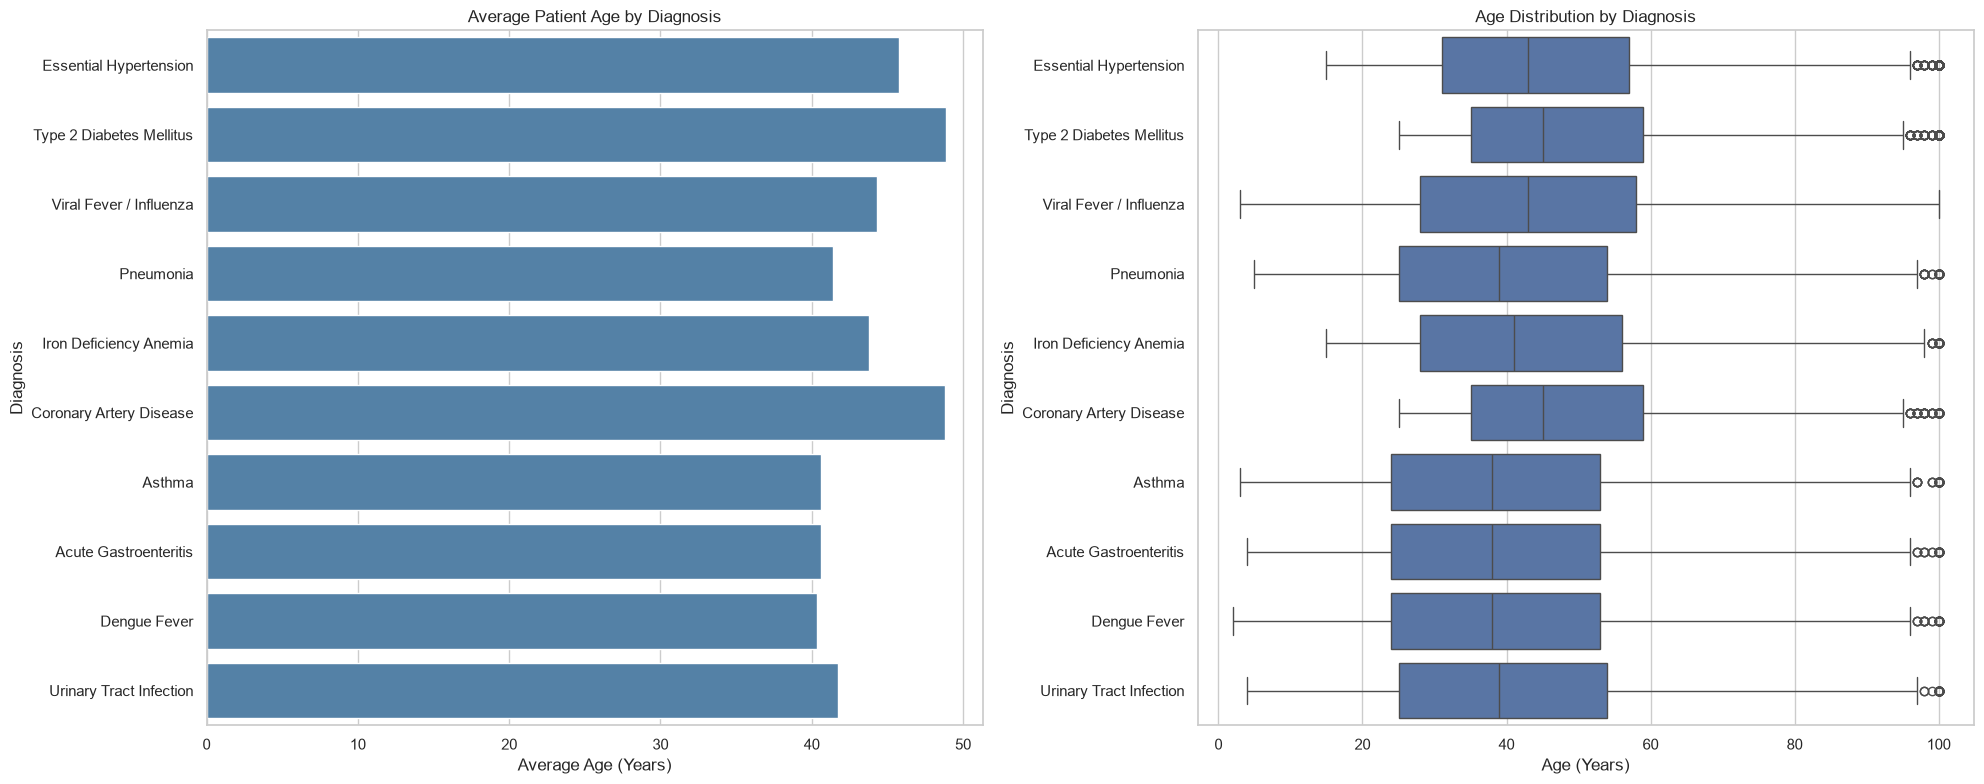

In [21]:
top_10_diagnoses = diagnosis_frequency.head(10)["diagnosis"]
age_plot_data = df[df["primary_diagnosis"].isin(top_10_diagnoses)].copy()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.barplot(data=age_diagnosis.reset_index().head(10), x="average_age", y="primary_diagnosis",
            color="steelblue", ax=axes[0])
axes[0].set_title("Average Patient Age by Diagnosis")
axes[0].set_xlabel("Average Age (Years)")
axes[0].set_ylabel("Diagnosis")

sns.boxplot(data=age_plot_data, x="age", y="primary_diagnosis",
            order=top_10_diagnoses.tolist(), ax=axes[1])
axes[1].set_title("Age Distribution by Diagnosis")
axes[1].set_xlabel("Age (Years)")
axes[1].set_ylabel("Diagnosis")

plt.tight_layout()
plt.show()

Hypertension is the most common diagnosis. Diabetes, Coronary Artery Disease, and Osteoarthritis are more common in older patients, while Asthma, Dengue Fever, and Gastroenteritis appear more often in younger groups. Most diagnoses have average patient ages between 40 and 50 years.

# Diagnoses with the highest risk scores

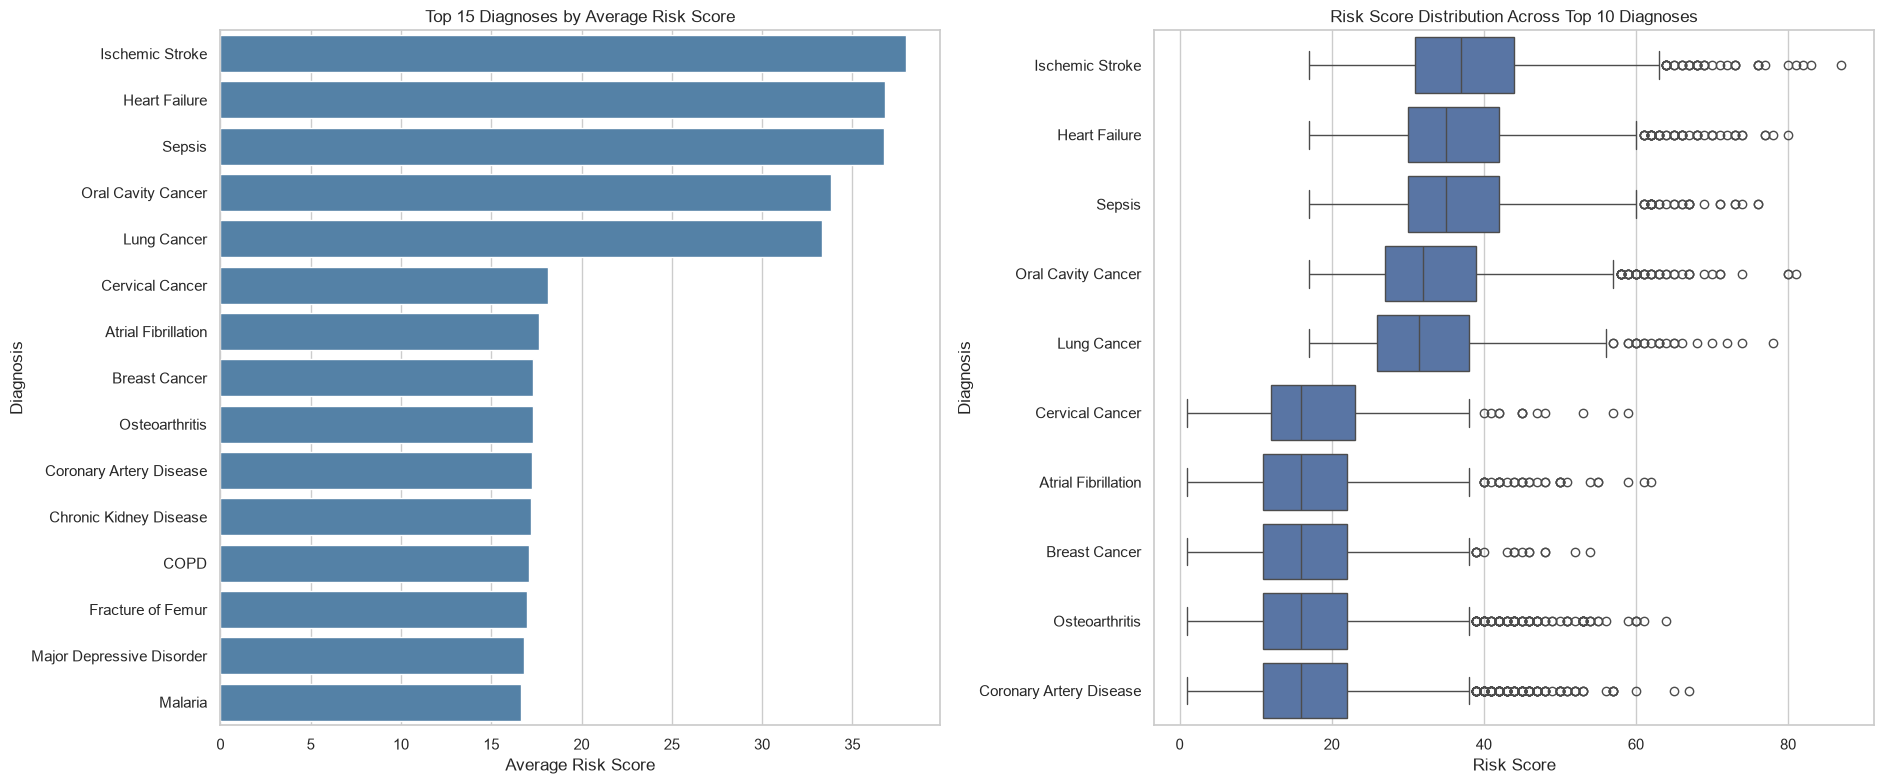

In [22]:
risk_by_diagnosis = df.groupby("primary_diagnosis").agg(
    patient_count = ("patient_id", "count"),
    average_risk  = ("risk_score", "mean"),
    median_risk   = ("risk_score", "median")
).sort_values("average_risk", ascending=False)

top_10_risk = risk_by_diagnosis.head(10).index
risk_plot_data = df[df["primary_diagnosis"].isin(top_10_risk)].copy()

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

sns.barplot(data=risk_by_diagnosis.reset_index().head(15),
            x="average_risk", y="primary_diagnosis", color="steelblue", ax=axes[0])
axes[0].set_title("Top 15 Diagnoses by Average Risk Score")
axes[0].set_xlabel("Average Risk Score")
axes[0].set_ylabel("Diagnosis")

sns.boxplot(data=risk_plot_data, x="risk_score", y="primary_diagnosis",
            order=top_10_risk.tolist(), ax=axes[1])
axes[1].set_title("Risk Score Distribution Across Top 10 Diagnoses")
axes[1].set_xlabel("Risk Score")
axes[1].set_ylabel("Diagnosis")

plt.tight_layout()
plt.show()

Ischemic Stroke has the highest average risk score, followed by Heart Failure and Sepsis. Cancer-related conditions also show elevated risk, and cardiovascular conditions consistently rank among the most severe. Risk varies substantially even within the same diagnosis category.

# Correlation Between Patient and Hospital Variables

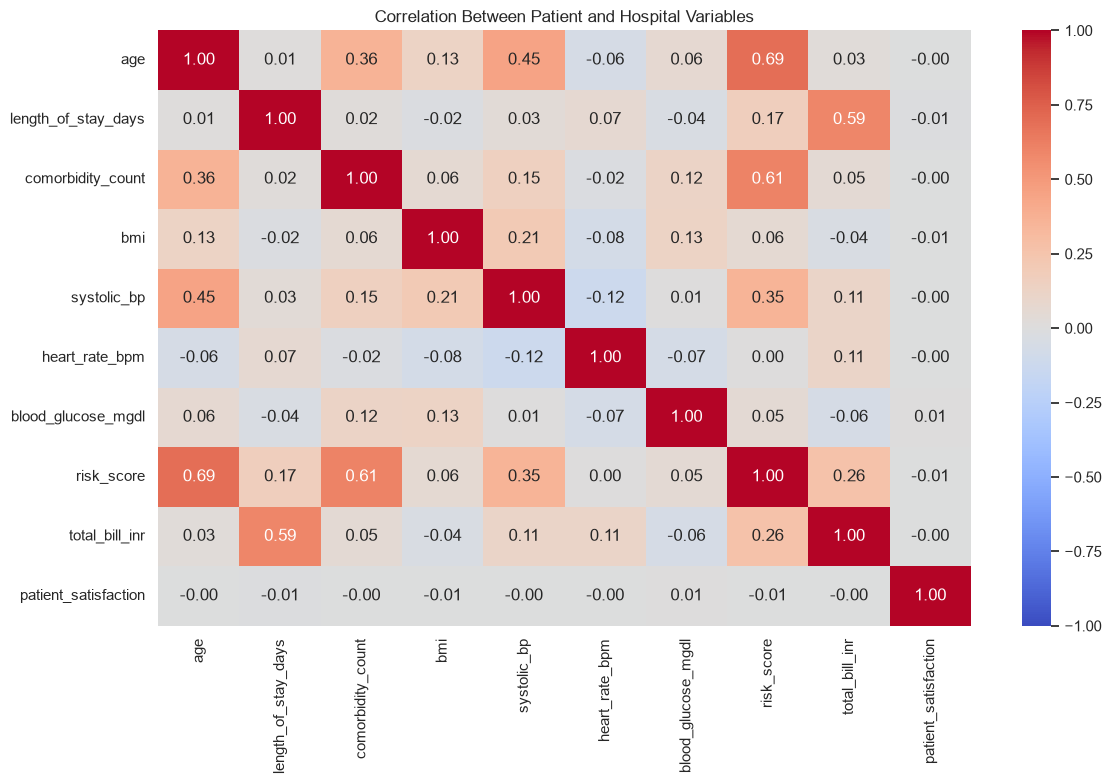

In [23]:
numeric_cols = [
    "age", "length_of_stay_days", "comorbidity_count", "bmi",
    "systolic_bp", "heart_rate_bpm", "blood_glucose_mgdl",
    "risk_score", "total_bill_inr", "patient_satisfaction"
]

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1
)
plt.title("Correlation Between Patient and Hospital Variables")
plt.tight_layout()
plt.show()

# Strong positive correlation = both go up together
# Strong negative correlation = one goes up, other goes down
# Near 0 = no real relationship

Age is the strongest factor associated with higher patient risk. Patients with more comorbidities and longer hospital stays tend to have higher risk scores and medical costs. Higher systolic blood pressure is also linked to greater health risk. Patient satisfaction does not appear to be strongly associated with the demographic, clinical, or financial variables in this dataset.